In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Analytical Solution

$T_{ss}(z) = T_b + \left(T_s - T_b\right)\frac{z}{L}$


$T(z,t) = T_{ss}(z) + \sum_{n=1}^{\infty} B_n \sin\!\left(\frac{n\pi z}{L}\right)\exp\!\left[-\kappa\left(\frac{n\pi}{L}\right)^{2} t\right]$



$B_n = \frac{2}{L}\int_{0}^{L}\left[T_0(z) - T_{ss}(z)\right] \sin\!\left(\frac{n\pi z}{L}\right)\,dz$


$T_{ss}(z) = -\frac{T_b}{L}\,z + T_b$


$T_0(z) = 0.002011z^{3} - 0.05199z^{2} + 0.1666z - 0.8$


In [25]:
#Setting up computation domain
k_c = 2.1
rho_i = 917
c_p = 2009
kappa = k_c / (rho_i * c_p)

year = 365.25 * 24 * 3600

B = year
omega = 2 * np.pi / B
dT_s = 10
Q_a = dT_s * np.sqrt(omega * k_c * rho_i * c_p)

T_b = -0.8
T_s = 0.0

L = 23.0 #fixed height since, no moving boundary condition
H_0 = L

#Initial condition
c3, c2, c1, c0 = 0.002011, -0.05199, 0.1666, -0.8
def initial_temperature(z):
    T0 = c3*z**3 + c2*z**2 + c1*z + c0
    T0[0] = T_b
    T0[-1] = T_s

    return T0

#Analytical Solution
z_a = np.linspace(0, L, 2000)
N_terms = 400 #fourier modes

#Steady state because we need homogeneous bounary conditions
T_steady = T_b + (T_s - T_b) * z_a / L
T_initial_a = initial_temperature(z_a)

n_values = np.arange(1, N_terms + 1)

B_n = np.zeros(N_terms) #save array for series coeffs

for n in n_values:
    integrand = (T_initial_a - T_steady) * np.sin(n * np.pi * z_a / L) 
    B_n[n - 1] = (2 / L) * np.trapezoid(integrand, z_a) #use trapezoid method to get coeffs, ORTHOGONALITY OF SINES

#analytical solution
def analytical_temperature(z, t):
    T_ss = T_b + (T_s - T_b) * z / L

    modes = (
        B_n[:, None]
        * np.sin(n_values[:, None] * np.pi * z[None, :] / L)
        * np.exp(
            -kappa
            * (n_values[:, None] * np.pi / L)**2
            * t
        )
    )

    return T_ss + np.sum(modes, axis=0)


#same timestepping as temp_evol_energy.ipynb
J = 100
dt = 86400.0

t_start = 0.0
t_end = 5 * year

N_steps = int(np.ceil((t_end - t_start) / dt))
time = np.linspace(t_start, t_end, N_steps + 1)
dt_actual = time[1] - time[0]

z_num = np.linspace(0, L, J + 2)

T_base = T_b
T_surface = T_s


#thomas alg.
def thomas(d, a, b, y):
    n = len(d)

    y_pp = np.zeros(n)
    a_p = np.zeros(n)

    a_p[0] = a[0] / d[0]
    y_pp[0] = y[0] / d[0]

    for i in range(1, n - 1):
        y_pp[i] = (y[i] - b[i] * y_pp[i - 1]) / (
            d[i] - b[i] * a_p[i - 1]
        )
        a_p[i] = a[i] / (d[i] - b[i] * a_p[i - 1])

        y_pp[n - 1] = (
            y[n - 1] - b[n - 1] * y_pp[n - 2]
        ) / (
            d[n - 1] - b[n - 1] * a_p[n - 2]
        )

        x = np.zeros(n)

    for i in range(n - 2, -1, -1):
        x[i] = y_pp[i] - a_p[i] * x[i + 1]

    return x


#implicit method
def solve_temperature_implicit(T_old, dt, H_old, J):

    dz = H_old / (J + 1)
    D = kappa * dt / dz**2

    d = np.ones(J) * (1 + 2 * D)
    a = np.ones(J) * (-D)
    b = np.ones(J) * (-D)

    y = T_old[1:-1].copy()
    y[0] += D * T_base
    y[-1] += D * T_surface

    T_interior = thomas(d, a, b, y)

    T_new = np.zeros(J + 2)
    T_new[0] = T_base
    T_new[-1] = T_surface
    T_new[1:-1] = T_interior

    return T_new


#set up initial condition for numerical solution
T_num = np.zeros((N_steps + 1, J + 2))
T_num[0, :] = initial_temperature(z_num)

for n in range(N_steps):
    T_num[n + 1, :] = solve_temperature_implicit(
        T_num[n, :],
        dt_actual,
        H_0,
        J
    )#loop through implicit method


ERROR STATISTICS
----------------------------------------
  Year       Max Error      Mean Error
     0   1.472198e-04   6.113256e-06
     1   5.073753e-02   2.156281e-02
     2   2.900584e-02   1.780402e-02
     3   1.983017e-02   1.346849e-02
     4   1.439553e-02   1.003817e-02
     5   1.104130e-02   7.672124e-03
----------------------------------------
Overall max error:  5.073753e-02 C
Overall mean error: 1.175862e-02 C


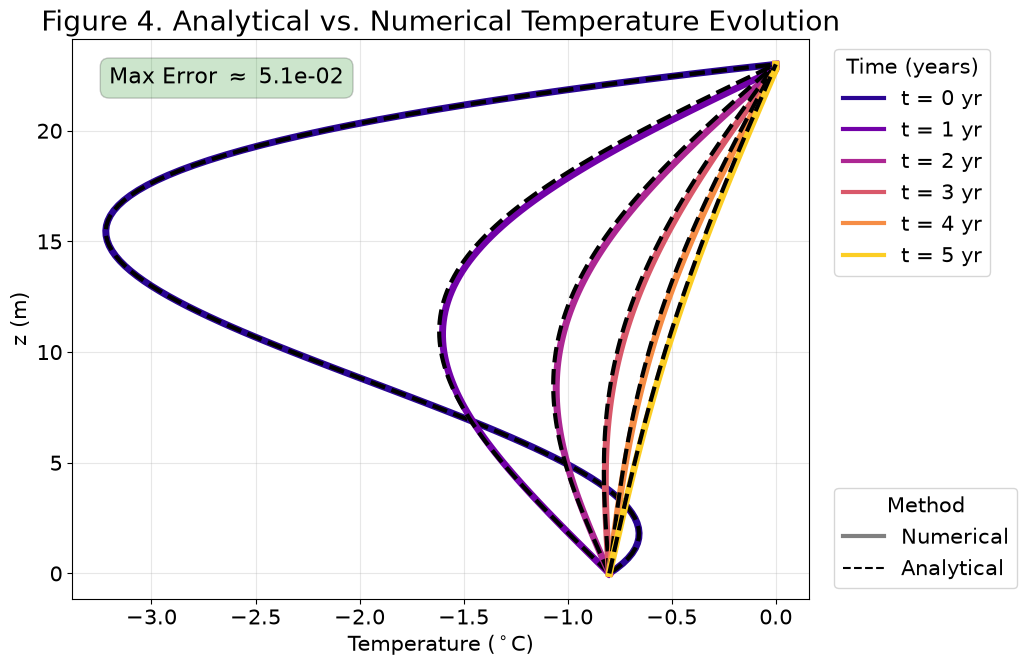

In [28]:
#interpolation to compare analytical and numerical results
def T_num_at(t):
    T_profile = np.zeros(J + 2)

    for j in range(J + 2):
        T_profile[j] = np.interp(
            t,
            time,
            T_num[:, j]
        )

    return T_profile

comparison_times = np.arange(0, 6) * year #select year 0 -> 5 for plotting
cmap = plt.get_cmap("plasma")
colors = [cmap(0.05 + 0.85 * i / 5) for i in range(6)]

fig, ax = plt.subplots(figsize=(11, 7))
error_results = []

for i, t in enumerate(comparison_times):
    T_num_t = T_num_at(t)
    T_ana_t = np.interp(z_num, z_a, analytical_temperature(z_a, t))
    err = np.abs(T_ana_t - T_num_t)
    error_results.append([t / year, err.max(), err.mean()])

    ax.plot(T_num_t, z_num, color=colors[i], lw=5) 
    ax.plot(T_ana_t, z_num, color="black", lw=3, ls="--")  

#errors
error_results = np.array(error_results)
print("\nERROR STATISTICS")
print("-" * 40)
print(f"{'Year':>6} {'Max Error':>15} {'Mean Error':>15}")
for row in error_results:
    print(f"{row[0]:6.0f}{row[1]:15.6e}{row[2]:15.6e}")
print("-" * 40)
print(f"Overall max error:  {error_results[:, 1].max():.6e} C")
print(f"Overall mean error: {error_results[:, 2].mean():.6e} C")

time_handles = [Line2D([0], [0], color=colors[i], lw=3, label=f"t = {i} yr")
                for i in range(6)]
style_handles = [
    Line2D([0], [0], color="gray", lw=3, label="Numerical"),
    Line2D([0], [0], color="black", lw=1.5, ls="--", label="Analytical"),
]

leg_time = ax.legend(handles=time_handles, title="Time (years)", fontsize=FS,
                     title_fontsize=FS, loc="upper left",
                     bbox_to_anchor=(1.02, 1.0))
ax.add_artist(leg_time)
ax.legend(handles=style_handles, title="Method", fontsize=FS,
          title_fontsize=FS, loc="lower left", bbox_to_anchor=(1.02, 0.0))

ax.set_xlabel(r"Temperature ($^\circ$C)", fontsize=FS)
ax.set_ylabel("z (m)", fontsize=FS)
ax.set_title("Figure 4. Analytical vs. Numerical Temperature Evolution", fontsize=20)
ax.tick_params(axis="both", labelsize=FS)
ax.grid(alpha=0.3)

plt.text(
    0.05, 0.95,
    rf'Max Error $\approx$ {error_results[:, 1].max():.1e}',
    transform=plt.gca().transAxes,
    fontsize=16,
    color = 'k',
    verticalalignment='top',
    bbox=dict(facecolor='green', alpha=0.2,
              edgecolor='black', boxstyle='round,pad=0.4')
)

fig.subplots_adjust(left=0.09, right=0.76, bottom=0.12, top=0.92)
plt.show()

fig.savefig("fig_4.png", dpi=300, bbox_inches="tight")